# Rainfall EDA (local)

Exploratory analysis of the Singapore rainfall data, running on **local Spark**.

The dataset is ~48.5M rows, so we never pull it all into pandas. The pattern throughout:
**aggregate or sample in Spark first, then plot the small result** with seaborn/matplotlib.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# from itables import init_notebook_mode

sys.path.insert(0, str(Path.cwd().parent))  # repo root, for `import config` / spark_project
from spark_project.session import create_local_spark
from pyspark.sql import functions as F

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# # Render pandas DataFrames as interactive (searchable / sortable) tables.
# init_notebook_mode(all_interactive=True)

PROJECT_DIR = Path.cwd().parent
PARQUET = str(PROJECT_DIR / "data/parquet")

In [2]:
# local[*] uses all cores.
# Session tz = Asia/Singapore: the Parquet timestamps are SGT wall-clock, so
# hour/month/date read back as local time directly (no manual +8 anywhere).
# driver_memory raised to 14g for Part 2's heavier joins / threshold expansion.
# Shuffle partitions left at the default (200): Part 2 shuffles tens of millions of
# rows, so the small fixed value used earlier would make each task too large and OOM.
# Adaptive Query Execution (on by default) coalesces the extra partitions for the
# small Part 1 aggregations, so the default is fine for both halves.
spark = create_local_spark(
    app_name="rainfall-eda",
    master="local[*]",
    driver_memory="14g",
    conf={"spark.sql.session.timeZone": "Asia/Singapore"},
)
spark

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/11 02:10:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/11 02:10:57 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


## Load the data

In [3]:
df = spark.read.parquet(PARQUET)
df.printSchema()
print("Rows:", df.count())
df.show(5, truncate=False)

root
 |-- date: date (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- update_timestamp: timestamp (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: double (nullable = true)
 |-- location_latitude: double (nullable = true)
 |-- reading_update_timestamp: timestamp (nullable = true)
 |-- reading_value: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)
 |-- year: integer (nullable = true)



Rows: 48538713


+----------+-------------------+-------------------+----------+-------------------+-----------------+------------------+-----------------+------------------------+-------------+-----------------------------+------------+----+
|date      |timestamp          |update_timestamp   |station_id|station_name       |station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type                 |reading_unit|year|
+----------+-------------------+-------------------+----------+-------------------+-----------------+------------------+-----------------+------------------------+-------------+-----------------------------+------------+----+
|2017-04-12|2017-04-12 01:49:59|2017-04-12 01:59:40|S44       |Nanyang Avenue     |S44              |103.68166         |1.34583          |2017-04-12 01:59:40     |0.0          |TB1 Rainfall 5 Minute Total F|mm          |2017|
|2017-04-12|2017-04-12 01:49:59|2017-04-12 01:59:40|S119      |Nicoll Highway     |S119         

## 1. Structure & keys

Before checking any values, confirm the table's shape:

1. **Grain** — is `(station_id, timestamp)` unique (one reading per station per time)?
2. **Entity integrity** — does each `station_id` map to a single location, device, and name, or do they drift over time?

In [4]:
# 1a. Grain: is (station_id, timestamp) unique?
# One groupBy-count pass; cheaper than a full distinct() over 48.5M rows.
dups = (
    df.groupBy("station_id", "timestamp")
    .count()
    .filter(F.col("count") > 1)
)
n_dup_keys = dups.count()
print(f"rows:                 {df.count():,}")
print(f"duplicated keys:      {n_dup_keys:,}")

# If any key repeats, inspect: same station+time, do the values agree?
if n_dup_keys:
    df.join(dups.drop("count"), ["station_id", "timestamp"]).orderBy(
        "station_id", "timestamp"
    ).show(10, truncate=False)
else:
    print("(station_id, timestamp) is unique — one reading per station per 5-min slot")

rows:                 48,538,713
duplicated keys:      0
(station_id, timestamp) is unique — one reading per station per 5-min slot


No duplicate keys, so there's exactly one reading per station per 5-minute slot. `(station_id, timestamp)` is the primary key.

In [5]:
# 1b. Entity integrity: how many stations have non-constant location / device / name?
entity = df.groupBy("station_id").agg(
    F.countDistinct("location_longitude", "location_latitude").alias("n_locations"),
    F.countDistinct("station_device_id").alias("n_devices"),
    F.countDistinct("station_name").alias("n_names"),
).cache()

summary = pd.DataFrame(
    {
        "attribute": ["location", "device", "name"],
        "stations_that_drift": [
            entity.filter(F.col("n_locations") > 1).count(),
            entity.filter(F.col("n_devices") > 1).count(),
            entity.filter(F.col("n_names") > 1).count(),
        ],
    }
)
summary

,attribute,stations_that_drift
0,location,1
1,device,0
2,name,26


Device ID is constant for every station. Two things aren't: 26 stations have more than one name, and one station has two locations. If either reflects a real change of station, `station_id` isn't a clean key. Checking both below.

In [6]:
# 1b (cont.) Stations that changed name: station_id -> list of names.
renamed = (
    df.groupBy("station_id")
    .agg(F.collect_set("station_name").alias("names"))
    .filter(F.size("names") > 1)
    .orderBy("station_id")
    .toPandas()
)
renamed

,station_id,names
0,S06,"[S06, Paya Lebar]"
1,S201,"[Clementi Park, S201]"
2,S203,"[Pasir Panjang, S203]"
3,S207,"[S207, Bedok Road]"
4,S208,"[S208, Changi East Close]"
5,S209,"[Yishun Ring Road, S209]"
6,S210,"[Woodlands Centre, S210]"
7,S211,"[Kranji Road, S211]"
8,S212,"[Tampines Avenue 9, S212]"
9,S213,"[S213, Coronation Walk]"


**Names.** Almost all of these are a code being replaced by a street name (S222 → Henderson Road). A few are just formatting variants of the same name (S215 capitalisation, S216 "Avenue" vs "Ave"). The device ID doesn't change in any case, so the name drift is relabelling, not a real change of station.

**Location.** The other case is the one station with two coordinates. The cell below computes how far apart they are and maps them, which tells us whether it's a real relocation or just GPS noise.

In [7]:
# Stations that changed location: station_id -> list of (lon, lat) pairs.
moved = (
    df.groupBy("station_id")
    .agg(F.collect_set(F.array("location_longitude", "location_latitude")).alias("locations"))
    .filter(F.size("locations") > 1)
    .orderBy("station_id")
    .toPandas()
)

import math

pts = moved.iloc[0]["locations"]  # [[lon, lat], [lon, lat]]
sid = moved.iloc[0]["station_id"]

# Distance between the two recorded coordinates (haversine, metres).
(lon1, lat1), (lon2, lat2) = pts
R = 6_371_000
p1, p2 = math.radians(lat1), math.radians(lat2)
dp = math.radians(lat2 - lat1)
dl = math.radians(lon2 - lon1)
a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
dist_m = 2 * R * math.asin(math.sqrt(a))
print(f"station:              {sid}")
print(f"coordinates:          {pts}")
print(f"distance apart:       {dist_m:.0f} m")

# Plot the two points on a real Singapore map. Fixed view: no drag, no zoom.
import folium

center = [(lat1 + lat2) / 2, (lon1 + lon2) / 2]
m = folium.Map(
    location=center,
    zoom_start=17,
    tiles="OpenStreetMap",
    zoom_control=False,
    scrollWheelZoom=False,
    dragging=False,
    touchZoom=False,
    doubleClickZoom=False,
    boxZoom=False,
    keyboard=False,
)
colors = ["blue", "orange", "red", "green"]
for i, (lon, lat) in enumerate(pts):
    folium.Marker(
        [lat, lon],
        popup=f"{sid} position {i + 1}: ({lon}, {lat})",
        icon=folium.Icon(color=colors[i % len(colors)]),
    ).add_to(m)
folium.PolyLine([[lat, lon] for lon, lat in pts], color="gray", dash_array="5").add_to(m)
m

station:              S113
coordinates:          [[103.91074, 1.30655], [103.9104, 1.30648]]
distance apart:       39 m


S113's two coordinates are 39m apart and the map puts them on the same block. That's within GPS noise for a fixed sensor, not a relocation. Same story as the names: neither drift reflects a real change of station, so `station_id` is a clean entity key — one device, one place per station.

## 2. Values & coverage

The structure holds up, so now check the values themselves:

1. **Schema constants** — is every row the same reading type and unit?
2. **Datetime** — do the timestamps sit on a clean 5-minute grid?
3. **Value validity** — nulls, negatives, range, and how often it actually rains.
4. **Per-station coverage** — how much data and how much rain each station has.

In [8]:
df.groupBy("reading_type", "reading_unit").count().toPandas()

,reading_type,reading_unit,count
0,TB1 Rainfall 5 Minute Total F,mm,48538713


One type and one unit across every row (5-minute rainfall total, in mm). Nothing's mixed, so the values are comparable and we can drop these two columns.

In [9]:
from pyspark.sql import Window
station_window = Window.partitionBy("station_id").orderBy("timestamp")

df.select(F.min("timestamp").alias("first"), F.max("timestamp").alias("last")).show(truncate=False)

# Calculate interval in seconds to the previous reading
df_intervals = (
    df.withColumn("prev_ts", F.lag("timestamp").over(station_window))
    .withColumn(
        "interval_seconds",
        F.unix_timestamp("timestamp") - F.unix_timestamp("prev_ts")
    )
)

# Summarize frequency of observed intervals
df_intervals.filter(F.col("interval_seconds").isNotNull()) \
    .groupBy("interval_seconds") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(10)

+-------------------+-------------------+
|first              |last               |
+-------------------+-------------------+
|2017-01-01 08:04:59|2024-12-31 23:55:00|
+-------------------+-------------------+



+----------------+--------+
|interval_seconds|   count|
+----------------+--------+
|             300|48342903|
|             600|   94523|
|             900|   57580|
|            1200|   12739|
|            1500|    7802|
|            1800|    3582|
|            2100|    2029|
|            2700|    1627|
|            2400|    1445|
|            3000|    1058|
+----------------+--------+
only showing top 10 rows



Readings runs 2017 to end of 2024.  They are primarily captured at 5-minute intervals ($99.6\%$ of records), consistent with the TB1 Rainfall 5 Minute Total F standard. 
While missing periods create longer gaps, all observed intervals remain exact multiples of 5 minutes.

In [10]:
import pyspark.sql.functions as F

# General check: Which seconds show up in our data by year?
(
    df.withColumn("second", F.second("timestamp"))
    .groupBy("year", "second")
    .count()
    .orderBy("year", "second")
    .show(60)
)

+----+------+-------+
|year|second|  count|
+----+------+-------+
|2017|     0|3480779|
|2017|    59|1775327|
|2018|     0|4594246|
|2019|     0|5026862|
|2020|     0|6334473|
|2021|     0|7044646|
|2022|     0|7133230|
|2023|     0|6742890|
|2024|     0|6406260|
+----+------+-------+



There also seems to be 1 quirk as some of 2017's readings land a second early.  Some processing will have to be done to `timestamp` to be used.

In [11]:
# 2c. Value validity: nulls, negatives, range, and how often it rains.
n = df.count()
df.select(
    F.sum(F.col("reading_value").isNull().cast("int")).alias("nulls"),
    F.sum((F.col("reading_value") < 0).cast("int")).alias("negatives"),
    F.min("reading_value").alias("min"),
    F.max("reading_value").alias("max"),
).show()

zeros = df.filter(F.col("reading_value") == 0).count()
print(f"zeros:    {zeros:,} of {n:,}  ({zeros / n * 100:.1f}%)")
print(f"nonzero:  {n - zeros:,}  ({(n - zeros) / n * 100:.1f}%)")

+-----+---------+---+----+
|nulls|negatives|min| max|
+-----+---------+---+----+
|    0|        0|0.0|37.2|
+-----+---------+---+----+



zeros:    47,121,730 of 48,538,713  (97.1%)
nonzero:  1,416,983  (2.9%)


In [12]:
per_station = (
    df.groupBy("station_id")
    .agg(
        F.count("*").alias("n"),
        F.round(F.avg((F.col("reading_value") > 0).cast("int")), 4).alias("wet_frac"),
        F.round(F.avg(F.when(F.col("reading_value") > 0, F.col("reading_value"))), 3).alias("mean_nz"),
        F.round(F.expr("percentile_approx(CASE WHEN reading_value > 0 THEN reading_value END, 0.99)"), 2).alias("p99"),
        F.round(F.max("reading_value"), 1).alias("max"),
    )
    .orderBy("wet_frac")  # driest / dead stations first
    .toPandas()
)
per_station

,station_id,n,wet_frac,mean_nz,p99,max
0,S24B,32648,0.0000,NaN,NaN,0.0
1,S97,6,0.0000,NaN,NaN,0.0
2,S72,33,0.0000,NaN,NaN,0.0
3,S103,45,0.0000,NaN,NaN,0.0
4,S208,470297,0.0216,0.776,5.71,10.8
...,...,...,...,...,...,...
86,S203,460068,0.0333,0.974,7.84,13.9
87,S201,470283,0.0340,0.906,7.20,13.6
88,S202,276164,0.0342,0.946,7.27,13.1
89,S228,467982,0.0346,0.984,7.52,17.6


Four stations sit at `wet_frac = 0`, all with very low `n`.  

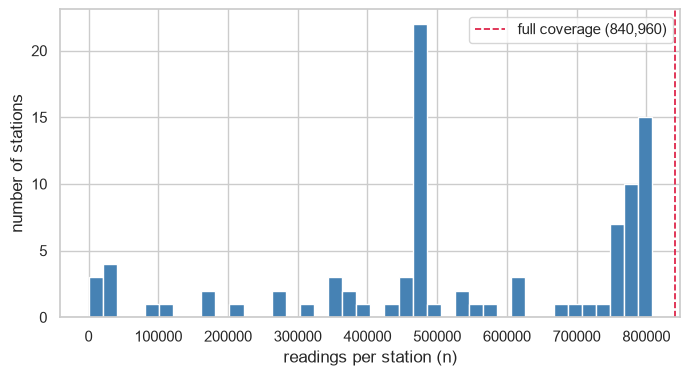

In [13]:
# Distribution of readings per station, against full coverage.
full = 24 * 60 // 5 * 365 * 8  # 5-min slots in 8 years

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_station["n"], bins=40, color="steelblue", edgecolor="white")
ax.axvline(full, color="crimson", ls="--", lw=1.2, label=f"full coverage ({full:,})")
ax.set(xlabel="readings per station (n)", ylabel="number of stations")
ax.legend()
plt.show()

There seems to be a problem with coverage as `n` ranges from 6 to about 808k. A station reporting every 5 minutes across 2017–2024 would have 840,960 entries, but many are way below that.

In [14]:

station_lifespan = df.groupBy("station_id").agg(
    F.min("timestamp").alias("first_seen"),
    F.max("timestamp").alias("last_seen"),
    F.count("*").alias("n")
).withColumn(
    # (last_seen - first_seen) in seconds divided by 300 (5 mins) + 1 for inclusive start point
    "theoretical_n", 
    (F.col("last_seen").cast("long") - F.col("first_seen").cast("long")) / 300+1
).withColumn(
    # Calculate percentage (e.g. 98.50%)
    "completeness_pct", 
    F.round((F.col("n") / F.col("theoretical_n")) * 100, 2)
).orderBy("first_seen", "last_seen")

total_stations = station_lifespan.count()
station_lifespan.show(n=total_stations, truncate=False)

+----------+-------------------+-------------------+------+------------------+----------------+
|station_id|first_seen         |last_seen          |n     |theoretical_n     |completeness_pct|
+----------+-------------------+-------------------+------+------------------+----------------+
|S110      |2017-01-01 08:04:59|2017-04-07 04:34:59|27573 |27607.0           |99.88           |
|S96       |2017-01-01 08:04:59|2017-04-18 04:04:59|30633 |30769.0           |99.56           |
|S24B      |2017-01-01 08:04:59|2017-04-25 11:24:59|32648 |32873.0           |99.32           |
|S63       |2017-01-01 08:04:59|2017-12-19 09:55:00|93890 |101399.00333333333|92.59           |
|S101      |2017-01-01 08:04:59|2018-12-07 09:45:00|169959|203061.00333333333|83.7            |
|S55       |2017-01-01 08:04:59|2019-02-21 11:20:00|206417|224968.00333333333|91.75           |
|S46       |2017-01-01 08:04:59|2020-12-04 17:10:00|355820|412814.00333333336|86.19           |
|S122      |2017-01-01 08:04:59|2021-09-

Most of that variance in `n` seems to be due to differences in the start and end datetimes.  However, there are stations that have pretty bad data completeness.

In [15]:
win = df.filter(
    (F.col("timestamp") >= "2017-01-01 08:04:59")
    & (F.col("timestamp") <= "2017-04-25 11:24:59")
)
(
    win.groupBy("station_id")
    .agg(
        F.count("*").alias("n"),
        F.round(F.avg((F.col("reading_value") > 0).cast("int")), 4).alias("wet_frac"),
        F.round(F.max("reading_value"), 1).alias("max"),
    )
    .orderBy("wet_frac")
    .show(100)
)

+----------+-----+--------+----+
|station_id|    n|wet_frac| max|
+----------+-----+--------+----+
|      S24B|32648|     0.0| 0.0|
|       S97|    6|     0.0| 0.0|
|       S72|   33|     0.0| 0.0|
|      S103|   45|     0.0| 0.0|
|       S60|13618|  0.0151| 7.6|
|       S89|25765|  0.0169|11.2|
|      S102|28038|  0.0226| 9.4|
|       S96|30633|  0.0243| 9.8|
|      S116|32791|  0.0264| 6.6|
|       S71|30500|  0.0271|10.2|
|      S112|31923|  0.0278| 8.6|
|       S33|32829|  0.0278|14.2|
|       S92|31020|  0.0279| 9.4|
|       S63|30766|  0.0291| 9.4|
|       S77|32839|  0.0294|11.6|
|      S122|32760|  0.0294|10.8|
|      S107|32649|  0.0295| 7.6|
|       S69|27467|  0.0298| 9.8|
|      S115|32399|  0.0302|11.6|
|       S66|32752|  0.0304|12.6|
|       S24|32336|  0.0305| 8.4|
|      S113|32181|  0.0309| 7.2|
|      S117|32753|  0.0309| 9.2|
|       S79|32721|  0.0309|10.0|
|      S120|31877|  0.0311| 9.0|
|      S119|32786|  0.0316| 9.4|
|       S90|30732|  0.0316|11.8|
|       S9

Additionally, S24B also seems to have a stuck sensor, reporting 0 wet periods even though it had a high completeness

## 3. Cleaning

Two fixes before any analysis:

1. **Timestamp** — add one second and truncate to the minute, so 2017's `:04:59` readings land on the clean 5-minute grid.
2. **Drop bad stations** — remove a station if it has too little data (`n < 1000`), poor completeness over its own lifespan (`< 90%`), or a stuck sensor (`wet_frac == 0`).

In [16]:
# Per-station quality: completeness over its own lifespan, and whether it ever records rain.
quality = df.groupBy("station_id").agg(
    F.count("*").alias("n"),
    ((F.max("timestamp").cast("long") - F.min("timestamp").cast("long")) / 300 + 1).alias("theoretical_n"),
    F.avg((F.col("reading_value") > 0).cast("int")).alias("wet_frac"),
).withColumn("completeness_pct", F.round(F.col("n") / F.col("theoretical_n") * 100, 2))

keep = quality.filter(
    (F.col("n") >= 1000) & (F.col("completeness_pct") >= 90) & (F.col("wet_frac") > 0)
)
keep_ids = [r["station_id"] for r in keep.select("station_id").collect()]

# What gets dropped, and why.
dropped = quality.filter(~F.col("station_id").isin(keep_ids)).withColumn(
    "reason",
    F.when(F.col("n") < 1000, "micro-coverage (n<1000)")
    .when(F.col("completeness_pct") < 90, "low completeness (<90%)")
    .otherwise("stuck sensor (wet_frac=0)"),
)
print(f"keep: {len(keep_ids)}   drop: {quality.count() - len(keep_ids)}")
dropped.select("station_id", "n", "completeness_pct", "wet_frac", "reason").orderBy("reason", "station_id").show(50, truncate=False)

# 1. Fix timestamps: +1s then truncate to the minute (aligns 2017's :04:59 to the grid).
# 2. Keep only the good stations.
# 3. Dedupe (station_id, timestamp): the +1s truncation collapses the 2017 boundary pair
#    (a :59 reading and the following :00 reading rounding to the same slot) — ~58 rows.
#    Values agree at the boundary, so dropping the duplicate is safe and keeps the key unique.
df_clean = (
    df.withColumn("timestamp", F.date_trunc("minute", F.col("timestamp") + F.expr("INTERVAL 1 SECOND")))
    .filter(F.col("station_id").isin(keep_ids))
    .dropDuplicates(["station_id", "timestamp"])
)
print(f"\nrows: {df.count():,} -> {df_clean.count():,}   stations kept: {len(keep_ids)}")

keep: 67   drop: 24


+----------+------+----------------+--------------------+-------------------------+
|station_id|n     |completeness_pct|wet_frac            |reason                   |
+----------+------+----------------+--------------------+-------------------------+
|S06       |40141 |4.77            |0.03667073565680975 |low completeness (<90%)  |
|S07       |554703|65.92           |0.029715000639982118|low completeness (<90%)  |
|S101      |169959|83.7            |0.030007237039521295|low completeness (<90%)  |
|S102      |181592|22.88           |0.024136525838142648|low completeness (<90%)  |
|S106      |620780|73.78           |0.02609620155288508 |low completeness (<90%)  |
|S108      |606751|73.52           |0.02666332647164982 |low completeness (<90%)  |
|S109      |750767|89.22           |0.03035162706938371 |low completeness (<90%)  |
|S117      |568651|67.58           |0.027475551788355247|low completeness (<90%)  |
|S122      |382247|77.32           |0.026315445248752768|low completeness (<


rows: 48,538,713 -> 39,537,417   stations kept: 67


24 stations dropped, 67 kept: 3 for near-empty coverage (S97, S72, S103), 20 for low completeness, and S24B for the stuck sensor. 

### Station map

Where the 67 kept stations sit across Singapore, for context before the analysis.

In [17]:
# Map of the 67 kept stations (one marker per station).
import folium

locs = (
    df_clean.groupBy("station_id")
    .agg(
        F.last("location_latitude").alias("lat"),
        F.last("location_longitude").alias("lon"),
        F.last("station_name").alias("name"),
    )
    .toPandas()
)

center = [locs["lat"].mean(), locs["lon"].mean()]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
for _, r in locs.iterrows():
    folium.CircleMarker(
        [r["lat"], r["lon"]], radius=4, color="steelblue", fill=True, fill_opacity=0.8,
        popup=f"{r['station_id']}: {r['name']}",
    ).add_to(m)
m

# Task 1: Weather patterns

Explore the weather patterns in the rainfall data and how they change within a year and across 2017–2024, using `df_clean`.

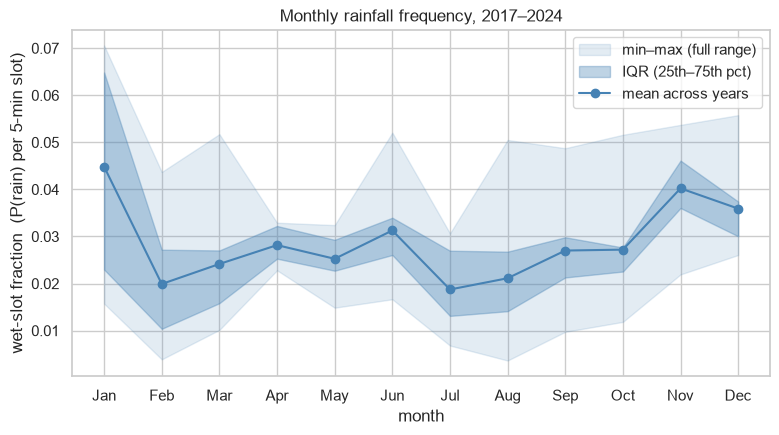

In [18]:
# A. Seasonal cycle: wet-slot fraction by month, with the 2017–2024 spread.
# Spatial-first: for each 5-min slot, take the fraction of active stations recording
# rain (one island-wide value per slot), then average those by (year, month). This
# weights each moment equally, so the changing station roster doesn't bias the result.
slot_wet = df_clean.groupBy("timestamp").agg(
    F.avg((F.col("reading_value") > 0).cast("int")).alias("slot_wet")
)
ym = (
    slot_wet.groupBy(F.year("timestamp").alias("year"), F.month("timestamp").alias("month"))
    .agg(F.avg("slot_wet").alias("wet_frac"))
    .toPandas()
)
piv = ym.pivot(index="month", columns="year", values="wet_frac").sort_index()

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), alpha=0.15, color="steelblue",
                label="min–max (full range)")
ax.fill_between(piv.index, piv.quantile(0.25, axis=1), piv.quantile(0.75, axis=1), alpha=0.35,
                color="steelblue", label="IQR (25th–75th pct)")
ax.plot(piv.index, piv.mean(axis=1), color="steelblue", marker="o", label="mean across years")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set(xlabel="month", ylabel="wet-slot fraction  (P(rain) per 5-min slot)",
       title="Monthly rainfall frequency, 2017–2024")
ax.legend()
plt.show()

The metric is the wet-slot fraction — the probability that a given 5-minute slot records rain, averaged first across the stations active in each slot, then over the slots in each (year, month). Averaging over stations first means the changing roster doesn't bias the result.

Rainfall frequency peaks over the Nov–Jan wet season (the Northeast Monsoon), ~0.045 in January, and falls to lows in February and July (~0.019) — about a 2.4× seasonal swing. The Southwest Monsoon (Jun–Sep) gives only a weak bump, not a distinct wet season.

The two shaded bands show inter-annual spread across 2017–2024: the IQR (25th–75th percentile) is the middle four of the eight years, the min–max band the full range. On average the IQR is about a third the width of min–max, so the full range is usually stretched by a single extreme year. January is the exception — its IQR is itself wide, so January frequency genuinely varies year to year. October is the opposite: a tight IQR under a wide min–max, i.e. one unusually wet October against otherwise consistent years.

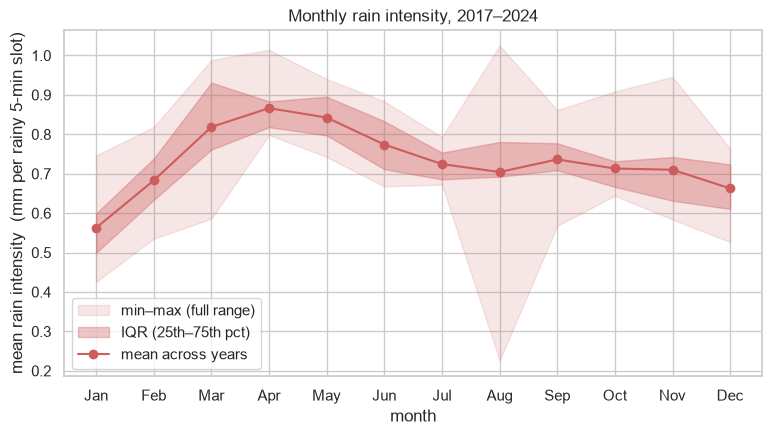

In [19]:
# B. Rain intensity: mean mm per RAINY slot, by month (conditional on it raining).
# Plot A showed how OFTEN it rains; this shows how HARD, when it does.
# Spatial-first: per slot, average over the stations that are raining (island-wide
# intensity for that moment), then average those by (year, month).
slot_int = (
    df_clean.filter(F.col("reading_value") > 0)
    .groupBy("timestamp")
    .agg(F.avg("reading_value").alias("slot_int"))
)
ymi = (
    slot_int.groupBy(F.year("timestamp").alias("year"), F.month("timestamp").alias("month"))
    .agg(F.avg("slot_int").alias("intensity"))
    .toPandas()
)
pivi = ymi.pivot(index="month", columns="year", values="intensity").sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(pivi.index, pivi.min(axis=1), pivi.max(axis=1), alpha=0.15, color="indianred",
                label="min–max (full range)")
ax.fill_between(pivi.index, pivi.quantile(0.25, axis=1), pivi.quantile(0.75, axis=1), alpha=0.35,
                color="indianred", label="IQR (25th–75th pct)")
ax.plot(pivi.index, pivi.mean(axis=1), color="indianred", marker="o", label="mean across years")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set(xlabel="month", ylabel="mean rain intensity  (mm per rainy 5-min slot)",
       title="Monthly rain intensity, 2017–2024")
ax.legend()
plt.show()

This is conditional intensity — mean mm over rainy slots only, again averaged across stations per slot then over the month — so it measures how hard it rains given that it rains, the complement to A's frequency.

Intensity runs opposite to frequency. January, the most frequent month, has the *lightest* rain per slot (~0.56 mm); the heaviest falls in the March–April inter-monsoon transition (~0.87 mm), then eases through the rest of the year. So the Nov–Jan wet season is wet because it rains more often, not harder — steady light monsoon rain — while the drier transition months deliver fewer but heavier convective bursts.

The seasonal range is modest (~1.5× peak-to-trough, vs ~2.4× for frequency), so frequency is the dominant driver of seasonal wetness. The bands behave as in A: a fairly tight IQR with wider min–max excursions from single outlier years.

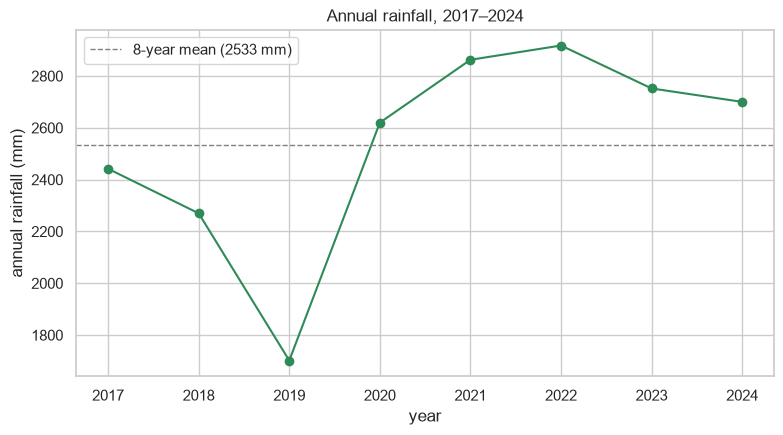

In [20]:
# C. Inter-annual totals: annual rainfall per year, 2017–2024.
# Spatial-first and roster-proof: for each 5-min slot, average reading_value over the
# stations present (the island-wide depth for that slot), then SUM those slot means
# over the year. A station joining or leaving mid-year only affects the slots it was
# actually present for — it can't contribute a partial-year "annual total".
slot_mm = df_clean.groupBy("timestamp").agg(F.avg("reading_value").alias("slot_mm"))
annual = (
    slot_mm.groupBy(F.year("timestamp").alias("yr"))
    .agg(F.sum("slot_mm").alias("mm"))
    .toPandas()
    .sort_values("yr")
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(annual["yr"], annual["mm"], marker="o", color="seagreen")
ax.axhline(annual["mm"].mean(), color="gray", ls="--", lw=1,
           label=f"8-year mean ({annual['mm'].mean():.0f} mm)")
ax.set_xticks(range(2017, 2025))
ax.set(xlabel="year", ylabel="annual rainfall (mm)", title="Annual rainfall, 2017–2024")
ax.legend()
plt.show()

Annual totals come from the island-average slot depth summed over each year, so a station joining or leaving mid-year only contributes to the slots it was present for — no partial-year total can distort the number. Totals land in the 1,700–2,900 mm range (8-year mean ~2,530 mm), consistent with Singapore's ~2,100–2,400 mm climatological norm.

There is no monotonic trend over the eight years. 2019 stands out as a distinctly dry year (~1,700 mm), 2021–2022 the wettest (~2,900 mm), easing slightly into 2023–2024. With only eight data points and high year-to-year noise, this reflects natural variability rather than a meaningful trend. Fitting a regression line here would over-interpret a sparse dataset.

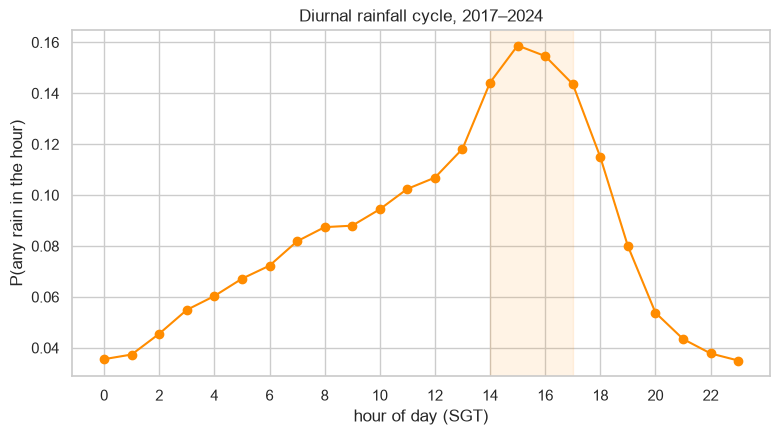

In [21]:
# D. Diurnal cycle: probability a given hour sees any rain, by hour of day (SGT).
# Timestamps are stored in SGT, so F.hour() is already local — no conversion.
# Per (station, date, hour): did any 5-min slot in that hour record rain?
# Then average those 0/1 flags over all station-hours, grouped by hour of day.
hour_any = df_clean.groupBy(
    "station_id", F.to_date("timestamp").alias("d"), F.hour("timestamp").alias("hour")
).agg(F.max((F.col("reading_value") > 0).cast("int")).alias("any_rain"))
hourly = (
    hour_any.groupBy("hour")
    .agg(F.avg("any_rain").alias("p_rain"))
    .toPandas()
    .sort_values("hour")
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(hourly["hour"], hourly["p_rain"], marker="o", color="darkorange")
ax.axvspan(14, 17, alpha=0.1, color="darkorange")  # afternoon window
ax.set_xticks(range(0, 24, 2))
ax.set(xlabel="hour of day (SGT)", ylabel="P(any rain in the hour)",
       title="Diurnal rainfall cycle, 2017–2024")
plt.show()

This is the probability that a given hour records any rain (any of its 5-minute slots), by hour of day in Singapore local time — the natural metric for an hourly axis.

The cycle is sharp: a broad overnight minimum (~0.035 around 22:00–01:00), a steady morning rise, then a peak at 15:00–16:00 (~0.16) before falling off through the evening — roughly a 4.5× swing from quietest to wettest hour, a bigger contrast than the seasonal or inter-annual variation.

Rain is strongly concentrated in the mid-afternoon. Hour of day is the strongest single driver of rainfall frequency in this data — a larger effect than month or year.

### Summary

Across the three time scales:

- **Within a year** — rain is most frequent in the Nov–Jan wet season, but *less* intense per shower; the heaviest rain falls in the Mar–Apr transition. Seasonal wetness is driven by how often it rains, not how hard.
- **Across years** — annual totals swing between ~1,700 and ~2,900 mm (2019 dry, 2021–2022 wet) with no trend over 2017–2024; this is year-to-year variability.
- **Within a day** — by far the strongest pattern: a sharp mid-afternoon peak, ~4.5× more likely to rain at 15:00 than overnight.

So hour of day is the dominant driver of rainfall frequency, ahead of season, with no detectable multi-year trend.

# Part 2: Modelling — probability of >X mm in the next 30 minutes

The goal is a model that, given a **station**, a **prediction time**, and a **rainfall threshold X**, estimates the probability the station accumulates more than X mm over the next 30 minutes. This notebook does the data preparation — it builds and writes a Parquet feature table; the model itself is trained separately by `scripts/train.py` (which reads that table).

The target at time `t` is the sum of the next six 5-minute readings (t+5 … t+30), labelled 1 if it exceeds X. Before fixing the threshold grid, we look at the distribution of that 30-minute accumulation.

A window is only usable if all six future slots (t+5 … t+30) are present on the grid. If any is missing we can't tell whether the threshold was exceeded, so the row is dropped rather than labelled 0 — calling an offline period "no rain" would train the model on a falsehood. The cell below marks these with `valid` and reports how many are lost.

In [22]:
# 2.1 Build the 30-minute forward accumulation and look at its distribution.
from pyspark.sql import Window

base = df_clean.select("station_id", "timestamp", "reading_value")

# Next six readings and their timestamps.
w = Window.partitionBy("station_id").orderBy(F.col("timestamp").cast("long"))
acc = base
for k in range(1, 7):
    acc = acc.withColumn(f"v{k}", F.lead("reading_value", k).over(w))
    acc = acc.withColumn(f"t{k}", F.lead(F.col("timestamp").cast("long"), k).over(w))

# A window is valid only if EVERY one of the six future slots is the exact consecutive
# 5-min step and carries a usable reading (non-null, non-negative). Checking all six —
# not just t6 — guards against a hole or stray value in the middle of the window, which
# would otherwise produce a NULL accum30 and a NULL (silently broken) label.
current_ts = F.col("timestamp").cast("long")
valid_cond = F.lit(True)
for k in range(1, 7):
    v = F.col(f"v{k}")
    valid_cond = (
        valid_cond
        & (F.col(f"t{k}") == current_ts + k * 300)
        & v.isNotNull()
        & ~F.isnan(v)
        & (v >= 0)
    )
acc = acc.withColumn("valid", valid_cond).withColumn(
    "accum30", sum(F.col(f"v{k}") for k in range(1, 7))
)
valid = acc.filter(F.col("valid")).select("station_id", "timestamp", "accum30")

# All distribution stats in a single aggregation (one Spark action over `valid`,
# instead of a separate count per threshold which would recompute the window each time).
THRESH_EDA = [0.2, 1, 2, 5, 10, 20]
stats = valid.agg(
    F.count("*").alias("n_valid"),
    F.avg((F.col("accum30") == 0).cast("double")).alias("dry_rate"),
    F.expr("percentile_approx(accum30, array(0.5,0.9,0.95,0.99,0.999))").alias("pct"),
    F.round(F.max("accum30"), 1).alias("max"),
    *[F.avg((F.col("accum30") > x).cast("double")).alias(f"rate_{x}") for x in THRESH_EDA],
).first()

n_base = base.count()
n_valid = stats["n_valid"]
print(f"base rows:            {n_base:,}")
print(f"valid 30-min windows: {n_valid:,}  ({n_valid / n_base * 100:.1f}%)")
print(f"completely dry:       {stats['dry_rate'] * 100:.1f}%")
print(f"percentiles [50/90/95/99/99.9]: {stats['pct']}   max: {stats['max']}")
for x in THRESH_EDA:
    print(f"  accum30 > {x:>4} mm:  {stats[f'rate_{x}'] * 100:5.2f}% positive")

base rows:            39,537,417
valid 30-min windows: 38,929,428  (98.5%)
completely dry:       93.8%
percentiles [50/90/95/99/99.9]: [0.0, 0.0, 0.2, 4.02, 20.799999999999997]   max: 85.6
  accum30 >  0.2 mm:   4.65% positive
  accum30 >    1 mm:   2.44% positive
  accum30 >    2 mm:   1.62% positive
  accum30 >    5 mm:   0.84% positive
  accum30 >   10 mm:   0.40% positive
  accum30 >   20 mm:   0.11% positive


Requiring a fully-observed future window drops only 1.5% of rows, so the validity rule is cheap. The accumulation is heavily zero-inflated: 93.8% of 30-minute windows are completely dry, the median and 90th percentile are both 0, and only the top ~1% exceed 4 mm.

Positive rates fall off fast with the threshold: 4.65% of windows exceed 0.2 mm, 1.62% exceed 2 mm, 0.84% exceed 5 mm, and above 10 mm it's under 0.4%. Beyond ~10 mm there are too few positives to train or evaluate on reliably.

So the **threshold grid is 0.2, 1, 2, 5, 10 mm** — spanning "any meaningful rain" to "heavy", each with enough positives (0.4%–4.7%) to learn from. Each base row is replicated once per threshold, with X as a feature and the label recomputed, so a single model answers any X at prediction time.

## 2.2 Build the training table

Features for each valid row at time `t`, all using information available at or before `t` (nothing from the target window):

- **Lags** — the station's own rainfall at `t, t−5, t−10, t−15, t−20`.
- **Spatial context at t** — across all stations at that timestamp: fraction raining, mean, max, standard deviation, and the number of stations reporting (so the model can tell a well-sampled statistic from a sparse one).
- **Cyclical time** — sine/cosine of minute-of-day and day-of-year. Minute-of-day (not integer hour) so the twelve 5-minute slots within an hour are distinguished.
- **Station** — `station_id` plus `lat`/`lon`.

The lags are built by joining on `timestamp − k·5min`, not by row offset, so if the earlier slot didn't transmit the lag is **missing** rather than silently picking up whatever row came before. The join yields NULL, left as a genuine missing value in the table — a missing slot differs from an observed zero, and filling with 0 would assert "it was dry" when we don't know. How missing is consumed is the training script's choice (`train.py` fills it with a sentinel for the tree model); the table itself stays model-neutral.

We deliberately keep the set lean: no rolling averages (the raw lags already carry the recent history at full resolution, and trees gain nothing from pre-aggregating features they already have) and no month encoding (redundant with day-of-year).

Finally each row is replicated once per threshold (0.2/1/2/5/10 mm) with the label `accum30 > X`, so a single model can take the threshold as an input and answer any X. The result is written to Parquet, partitioned by year for a cheap chronological split.

In [ ]:
# 2.2 Build the feature table, expand over thresholds, write to Parquet.
OUT = str(PROJECT_DIR / "data/train_table")
THRESHOLDS = [0.2, 1.0, 2.0, 5.0, 10.0]

dc = df_clean.select(
    "station_id", "timestamp",
    F.col("reading_value").alias("rain_t"),
    F.col("location_latitude").alias("lat"),
    F.col("location_longitude").alias("lon"),
)

# Gap-aware lags: join on (station, timestamp − k·5min). A missing earlier slot stays
# missing (NaN), rather than a row-offset F.lag silently pulling the previous surviving row.
feat = dc.withColumn("ts", F.col("timestamp").cast("long"))
for k, mins in [(1, 5), (2, 10), (3, 15), (4, 20)]:
    lag = dc.select(
        F.col("station_id").alias("s_"),
        (F.col("timestamp").cast("long") + k * 300).alias("tj_"),
        F.col("rain_t").alias(f"rain_t{mins}"),
    )
    feat = feat.join(lag, (feat.station_id == lag.s_) & (feat.ts == lag.tj_), "left").drop("s_", "tj_")

# Island-wide spatial context at t. isl_n_stations records how many stations reported
# that slot, so the model can tell a well-sampled statistic from a sparse one.
isl = dc.groupBy("timestamp").agg(
    F.avg((F.col("rain_t") > 0).cast("int")).alias("isl_frac_wet"),
    F.avg("rain_t").alias("isl_mean"),
    F.max("rain_t").alias("isl_max"),
    F.stddev("rain_t").alias("isl_std"),
    F.count("rain_t").alias("isl_n_stations"),
)
feat = feat.join(isl, "timestamp")

# Cyclical time. Hour uses minute-of-day so the 12 slots within an hour differ (5-min
# resolution), rather than all sharing the same integer-hour encoding.
mod = F.hour("timestamp") * 60 + F.minute("timestamp")  # minute of day, 0..1439
feat = (
    feat.withColumn("hour_sin", F.sin(2 * F.lit(math.pi) * mod / 1440))
    .withColumn("hour_cos", F.cos(2 * F.lit(math.pi) * mod / 1440))
    .withColumn("doy_sin", F.sin(2 * F.lit(math.pi) * F.dayofyear("timestamp") / 365))
    .withColumn("doy_cos", F.cos(2 * F.lit(math.pi) * F.dayofyear("timestamp") / 365))
    .withColumn("year", F.year("timestamp"))
)

# A left join yields NULL for a missing lag, and isl_std is NULL when only one station
# reported that slot. Convert both to an explicit float NaN so missing is a genuine
# value in the table rather than a type-ambiguous NULL. The table stays model-neutral;
# how missing is consumed is the training script's choice (train.py fills a sentinel).
for c in ["rain_t5", "rain_t10", "rain_t15", "rain_t20", "isl_std"]:
    feat = feat.withColumn(c, F.coalesce(F.col(c), F.lit(float("nan"))))

# Attach the label source (accum30) from 2.1, keep only valid windows.
feat = feat.join(valid.select("station_id", "timestamp", "accum30"), ["station_id", "timestamp"], "inner")

FEATURES = [
    "station_id", "lat", "lon",
    "rain_t", "rain_t5", "rain_t10", "rain_t15", "rain_t20",
    "isl_frac_wet", "isl_mean", "isl_max", "isl_std", "isl_n_stations",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
]
feat = feat.select(*FEATURES, "year", "timestamp", "accum30")

# Expand over thresholds and label. `threshold` is a feature at train time (MODEL_FEATURES
# below) so one model answers any X; `accum30 > X` matches the task's "more than X".
grid = spark.createDataFrame([(t,) for t in THRESHOLDS], ["threshold"])
train_table = (
    feat.crossJoin(F.broadcast(grid))
    .withColumn("label", (F.col("accum30") > F.col("threshold")).cast("int"))
    .drop("accum30")
)

# The training job (scripts/train.py) assembles its feature vector from these (incl. threshold).
MODEL_FEATURES = FEATURES + ["threshold"]

train_table.write.mode("overwrite").partitionBy("year").parquet(OUT)
print("wrote", OUT)